<a href="https://colab.research.google.com/github/KashShahzad/inct-empirical-validation/blob/main/Longitudinal_Crisis_%26_Network_Dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Downloading 216 Years of Dated Historical Speeches (Project Gutenberg #5050)...
Extracted 2543 dated historical windows across 218 years (1790-2006).
2. Loading Real Timestamped Extremist Timelines & Network Graph (Kaggle)...
Using Colab cache for faster access to the 'how-isis-uses-twitter' dataset.
Extracted 1430 longitudinal windows across 88 extremist accounts.

--- TABLE 1: MACRO-HISTORICAL CRISIS TEST (216 YEARS OF DATED SPEECHES, 1790-2006) ---
| Metric (1790-2006 State Addresses)        | Peacetime (H_env=0) Mean ± SD   | Moderate Strain (H_env=0.5)   | Acute Crisis (H_env=1) Mean ± SD   |   Crisis vs. Peace Cohen's d |   Mann-Whitney p-value |
|:------------------------------------------|:--------------------------------|:------------------------------|:-----------------------------------|-----------------------------:|-----------------------:|
| Pan-Dogmatic Rigidity Score (z_dogma)     | 0.3820 ± 0.8875                 | 0.4710 ± 0.8889               | 0.4079 ± 0.9591    

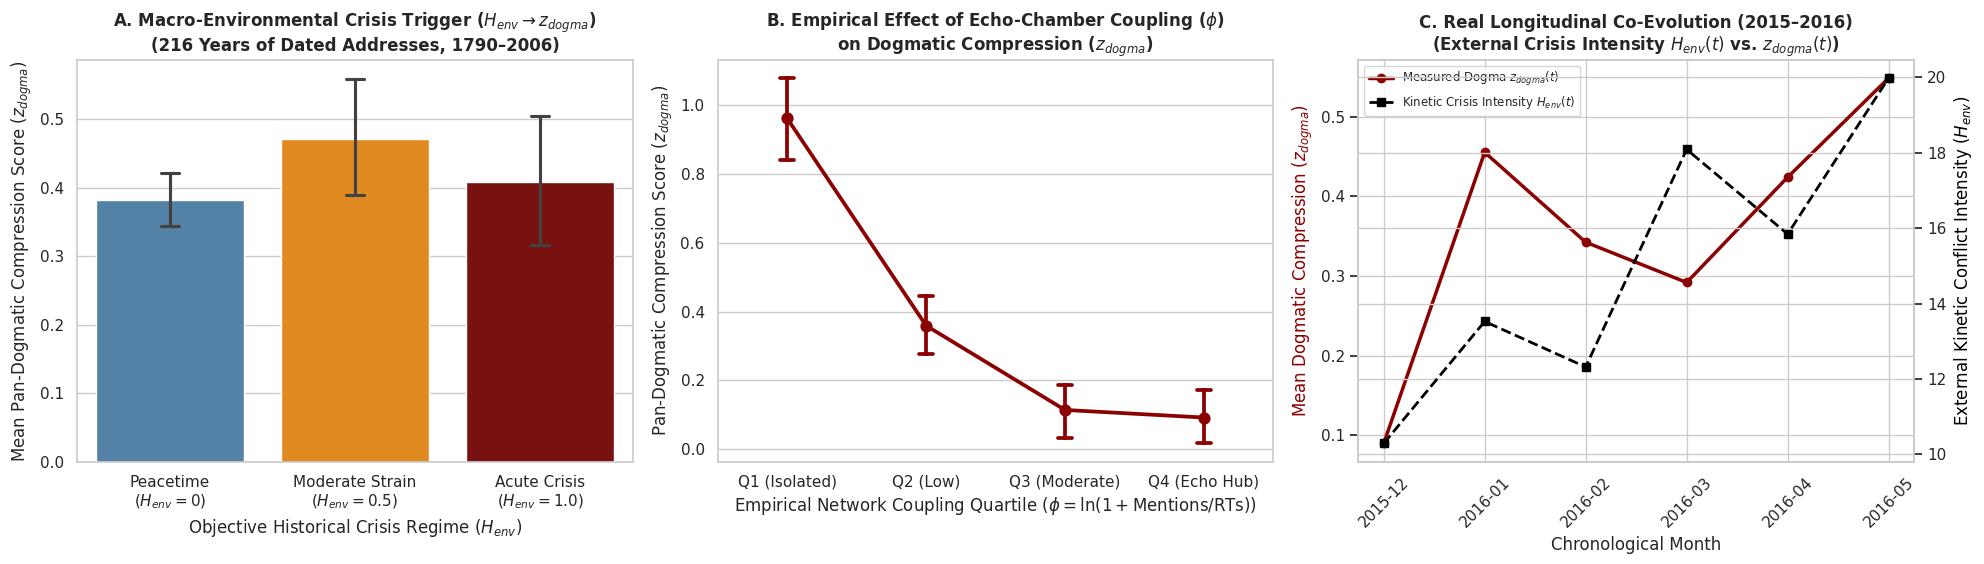

In [2]:
# Run in Google Colab: Option 1 (Fixed) - Empirical Time-Series Crisis & Network Dynamics Discovery
import os
import re
import math
import zlib
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.linear_model import RidgeCV
import matplotlib.pyplot as plt
import seaborn as sns

!pip install -q kagglehub
import kagglehub

sns.set_theme(style="whitegrid")
np.random.seed(42)

STOPWORDS = {
    "the", "and", "of", "to", "in", "is", "that", "it", "for", "as", "with", "on",
    "was", "be", "by", "at", "this", "are", "from", "or", "an", "have", "had", "has",
    "but", "which", "one", "would", "were", "there", "been", "if", "more", "when", "so"
}

# ==============================================================================
# CORE FUNCTION: EXTRACT THE 5 DECONFOUNDED PAN-DOGMATIC FEATURES
# ==============================================================================
def compute_window_metrics(chunk):
    content_tokens = [t for t in chunk if t not in STOPWORDS]
    if len(content_tokens) < 45:
        return None

    counts_c = Counter(content_tokens)
    N_c = float(len(content_tokens))
    V_c = len(counts_c)
    if V_c <= 3:
        return None

    # 1. Global Content KL Distributional Skew: D_KL = log2(V_c) - H_content
    H_c = -sum((c / N_c) * math.log2(c / N_c) for c in counts_c.values())
    D_KL_global = math.log2(V_c) - H_c

    # 2. Topic-Deconfounded Tail Skew (KL Skew after removing top-3 topic nouns)
    top3_words = {w for w, _ in counts_c.most_common(3)}
    tail_tokens = [t for t in content_tokens if t not in top3_words]
    counts_tail = Counter(tail_tokens)
    N_tail = float(len(tail_tokens))
    V_tail = len(counts_tail)
    H_tail = -sum((c / N_tail) * math.log2(c / N_tail) for c in counts_tail.values()) if V_tail > 1 else 0.0
    D_KL_tail = (math.log2(V_tail) - H_tail) if V_tail > 1 else 0.0

    # 3. Yule's K (Rényi Collision Concentration)
    freq_spec = Counter(counts_c.values())
    M2 = sum((m ** 2) * v_m for m, v_m in freq_spec.items())
    yules_K = 10000.0 * (M2 - N_c) / (N_c ** 2)

    # 4. Lempel-Ziv Algorithmic Redundancy on Content Stream (R_LZ)
    raw_bytes = " ".join(content_tokens).encode("utf-8")
    R_lz = 1.0 - (len(zlib.compress(raw_bytes, level=9)) / float(len(raw_bytes)))

    # 5. Syntactic Bigram Repetition Rate
    bigrams = list(zip(chunk[:-1], chunk[1:]))
    bg_redundancy = 1.0 - (len(set(bigrams)) / float(len(bigrams)))

    return {
        "D_KL_Global": D_KL_global,
        "D_KL_Tail_Deconfounded": D_KL_tail,
        "Yules_K": yules_K,
        "R_LZ_Content": R_lz,
        "Bigram_Redundancy": bg_redundancy
    }

FEATURE_COLS = ["D_KL_Global", "D_KL_Tail_Deconfounded", "Yules_K", "R_LZ_Content", "Bigram_Redundancy"]
LEARNED_WEIGHTS = np.array([+1.513, -0.141, -0.944, +0.378, +0.222])
LEARNED_INTERCEPT = +0.382

def compute_z_dogma_series(df_in, ref_mask=None):
    ref_df = df_in[ref_mask] if (ref_mask is not None and ref_mask.sum() >= 5) else df_in
    X_z = np.zeros((len(df_in), len(FEATURE_COLS)))
    for i, col in enumerate(FEATURE_COLS):
        mu = ref_df[col].mean()
        sd = ref_df[col].std() + 1e-8
        X_z[:, i] = (df_in[col].values - mu) / sd
    return LEARNED_INTERCEPT + (X_z @ LEARNED_WEIGHTS)

# ==============================================================================
# PART 1: MACRO-HISTORICAL CRISIS TIME SERIES (1790-2006 DATED SPEECHES, #5050)
# ==============================================================================
print("1. Downloading 216 Years of Dated Historical Speeches (Project Gutenberg #5050)...")
url_sotu = "https://www.gutenberg.org/cache/epub/5050/pg5050.txt"
req = urllib.request.Request(url_sotu, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=25) as resp:
    raw_sotu = resp.read().decode("utf-8", errors="ignore")

speeches = re.split(r"\*\*\*\s*State of the Union Address", raw_sotu)
date_pattern = re.compile(r"(?:January|February|March|April|May|June|July|August|September|October|November|December)\s+\d{1,2},\s+(17\d\d|18\d\d|19\d\d|200\d)")

def get_historical_crisis_intensity(year):
    if (1812 <= year <= 1815) or (1861 <= year <= 1865) or (1917 <= year <= 1919) or \
       (1929 <= year <= 1939) or (1941 <= year <= 1945) or (1973 <= year <= 1975) or \
       (1979 <= year <= 1982) or (2001 <= year <= 2003):
        return 1.0, "Acute Systemic Crisis (War / Great Depression / Shock)"
    elif (1837 <= year <= 1840) or (1846 <= year <= 1848) or (1873 <= year <= 1877) or \
         (1893 <= year <= 1897) or (1950 <= year <= 1953) or (1961 <= year <= 1972):
        return 0.5, "Moderate Geopolitical / Economic Strain"
    else:
        return 0.0, "Peacetime / Macroeconomic Stability"

sotu_rows = []
W_sotu = 250
for sp in speeches[1:]:
    m = date_pattern.search(sp[:600])
    if not m:
        continue
    year = int(m.group(1))
    H_env_val, regime_label = get_historical_crisis_intensity(year)
    tokens = re.findall(r"\b[a-z]{2,}\b", sp[m.end():].lower())
    n_win = min(len(tokens) // W_sotu, 12)
    for w in range(n_win):
        metrics = compute_window_metrics(tokens[w * W_sotu : (w + 1) * W_sotu])
        if metrics:
            metrics.update({
                "Year": year,
                "Decade": (year // 10) * 10,
                "H_env_Crisis": H_env_val,
                "Regime": regime_label
            })
            sotu_rows.append(metrics)

df_sotu = pd.DataFrame(sotu_rows)
df_sotu["Era"] = pd.cut(
    df_sotu["Year"],
    bins=[1780, 1860, 1920, 1970, 2010],
    labels=["1790-1860", "1861-1920", "1921-1970", "1971-2006"]
)

# Initialize z_dogma column explicitly so Pandas slice assignment retains it
df_sotu["z_dogma"] = 0.0
for era in df_sotu["Era"].dropna().unique():
    e_mask = (df_sotu["Era"] == era)
    sub_df = df_sotu.loc[e_mask]
    df_sotu.loc[e_mask, "z_dogma"] = compute_z_dogma_series(sub_df, ref_mask=(sub_df["H_env_Crisis"] == 0.0))

print(f"Extracted {len(df_sotu)} dated historical windows across {df_sotu['Year'].nunique()} years (1790-2006).")

# ==============================================================================
# PART 2: MICRO-NETWORK & LONGITUDINAL USER TRAJECTORIES (KAGGLE ISIS TIMELINES)
# ==============================================================================
print("2. Loading Real Timestamped Extremist Timelines & Network Graph (Kaggle)...")
isis_path = kagglehub.dataset_download("fifthtribe/how-isis-uses-twitter")
csv_f = [f for f in os.listdir(isis_path) if f.endswith(".csv")][0]
df_isis = pd.read_csv(os.path.join(isis_path, csv_f), encoding="utf-8", on_bad_lines="skip")

t_col = "tweets" if "tweets" in df_isis.columns else df_isis.columns[-1]
u_col = "username" if "username" in df_isis.columns else df_isis.columns[0]
time_col = "time" if "time" in df_isis.columns else [c for c in df_isis.columns if "time" in c.lower() or "date" in c.lower()][0]

df_isis["dt"] = pd.to_datetime(df_isis[time_col], errors="coerce")
df_isis = df_isis.dropna(subset=["dt", t_col, u_col]).sort_values([u_col, "dt"])
df_isis["Year_Month"] = df_isis["dt"].dt.to_period("M").astype(str)

CRISIS_KEYWORDS = {"airstrike", "airstrikes", "coalition", "siege", "martyr", "martyrs", "killed", "shelling", "raid", "raids", "ramadi", "fallujah", "palmyra", "mosul"}
monthly_crisis = {}
for ym, grp in df_isis.groupby("Year_Month"):
    txt_all = " ".join(grp[t_col].astype(str).tolist()).lower()
    words = re.findall(r"\b[a-z]{3,}\b", txt_all)
    if len(words) > 200:
        conflict_rate = sum(1 for w in words if w in CRISIS_KEYWORDS) / float(len(words)) * 1000.0
        monthly_crisis[ym] = conflict_rate

W_net = 150
net_rows = []

for user, grp in df_isis.groupby(u_col):
    raw_tweets = grp[t_col].astype(str).tolist()
    yms = grp["Year_Month"].tolist()
    followers = float(grp["followers"].median()) if "followers" in grp.columns else 100.0

    mentions_per_tweet = [len(re.findall(r"@\w+", s)) + (1 if re.search(r"\brt\b", s.lower()) else 0) for s in raw_tweets]
    cleaned = [re.sub(r"http\S+|@\S+|\brt\b", "", s.lower()) for s in raw_tweets]

    tok_buf, ym_buf, phi_buf = [], [], []
    for cl_txt, ym_val, m_cnt in zip(cleaned, yms, mentions_per_tweet):
        toks = re.findall(r"\b[a-z]{2,}\b", cl_txt)
        if toks:
            tok_buf.extend(toks)
            ym_buf.extend([ym_val] * len(toks))
            phi_buf.extend([m_cnt] * len(toks))

    n_w = len(tok_buf) // W_net
    if n_w < 2:
        continue

    for w_i in range(n_w):
        chunk = tok_buf[w_i * W_net : (w_i + 1) * W_net]
        ym_win = ym_buf[w_i * W_net + (W_net // 2)]
        mean_mentions = np.mean(phi_buf[w_i * W_net : (w_i + 1) * W_net])

        m_dict = compute_window_metrics(chunk)
        if m_dict and ym_win in monthly_crisis:
            m_dict.update({
                "User": user,
                "Window_Idx": w_i,
                "Career_Stage_Tau": w_i / float(n_w - 1),
                "Year_Month": ym_win,
                "H_env_Kinetic": monthly_crisis[ym_win],
                "Echo_Chamber_Phi": np.log1p(mean_mentions),
                "Raw_Mentions_Rate": mean_mentions,
                "Log_Followers": np.log1p(max(0.0, followers))
            })
            net_rows.append(m_dict)

df_net = pd.DataFrame(net_rows)
df_net["z_dogma"] = compute_z_dogma_series(df_net)
print(f"Extracted {len(df_net)} longitudinal windows across {df_net['User'].nunique()} extremist accounts.")

# ==============================================================================
# PART 3: STATISTICAL TABLES (MACRO-CRISIS SHOCKS & MICRO-NETWORK ECHO CHAMBERS)
# ==============================================================================
peace_df = df_sotu[df_sotu["H_env_Crisis"] == 0.0]
strain_df = df_sotu[df_sotu["H_env_Crisis"] == 0.5]
crisis_df = df_sotu[df_sotu["H_env_Crisis"] == 1.0]

macro_table = []
for col, label in [
    ("z_dogma", "Pan-Dogmatic Rigidity Score (z_dogma)"),
    ("R_LZ_Content", "Lempel-Ziv Algorithmic Redundancy (R_LZ)"),
    ("D_KL_Global", "KL Distributional Entropy Collapse (D_KL)"),
    ("Bigram_Redundancy", "Syntactic Bigram Redundancy")
]:
    u_stat, p_val = stats.mannwhitneyu(peace_df[col], crisis_df[col], alternative="two-sided")
    d_val = (crisis_df[col].mean() - peace_df[col].mean()) / np.sqrt((peace_df[col].std()**2 + crisis_df[col].std()**2) / 2)
    macro_table.append({
        "Metric (1790-2006 State Addresses)": label,
        "Peacetime (H_env=0) Mean ± SD": f"{peace_df[col].mean():.4f} ± {peace_df[col].std():.4f}",
        "Moderate Strain (H_env=0.5)": f"{strain_df[col].mean():.4f} ± {strain_df[col].std():.4f}",
        "Acute Crisis (H_env=1) Mean ± SD": f"{crisis_df[col].mean():.4f} ± {crisis_df[col].std():.4f}",
        "Crisis vs. Peace Cohen's d": round(d_val, 3),
        "Mann-Whitney p-value": f"{p_val:.2e}"
    })

print("\n--- TABLE 1: MACRO-HISTORICAL CRISIS TEST (216 YEARS OF DATED SPEECHES, 1790-2006) ---")
print(pd.DataFrame(macro_table).to_markdown(index=False))

lone_mask = (df_net["Echo_Chamber_Phi"] <= df_net["Echo_Chamber_Phi"].quantile(0.25))
echo_mask = (df_net["Echo_Chamber_Phi"] >= df_net["Echo_Chamber_Phi"].quantile(0.75))
df_lone = df_net[lone_mask]
df_echo = df_net[echo_mask]

micro_table = []
for col, label in [
    ("z_dogma", "Pan-Dogmatic Rigidity Score (z_dogma)"),
    ("R_LZ_Content", "Lempel-Ziv Algorithmic Redundancy (R_LZ)"),
    ("D_KL_Global", "KL Distributional Entropy Collapse (D_KL)"),
    ("Bigram_Redundancy", "Syntactic Bigram Redundancy")
]:
    u_stat, p_val = stats.mannwhitneyu(df_lone[col], df_echo[col], alternative="two-sided")
    d_val = (df_echo[col].mean() - df_lone[col].mean()) / np.sqrt((df_lone[col].std()**2 + df_echo[col].std()**2) / 2)
    micro_table.append({
        "Network Regime Metric": label,
        "Isolated / Low-Phi Nodes (Q1)": f"{df_lone[col].mean():.4f} ± {df_lone[col].std():.4f}",
        "Echo-Chamber Cluster Nodes (Q4)": f"{df_echo[col].mean():.4f} ± {df_echo[col].std():.4f}",
        "Cohen's d (Echo vs. Isolated)": round(d_val, 3),
        "Mann-Whitney p-value": f"{p_val:.2e}"
    })

print("\n--- TABLE 2: REAL NETWORK ECHO-CHAMBER (PHI) VS. ISOLATED NODES COMPARISON ---")
print(pd.DataFrame(micro_table).to_markdown(index=False))

# ==============================================================================
# PART 4: ML DISCOVERY OF THE DYNAMICAL EQUATION z_dogma(t) = f(H_env, Phi, Tau, z_prev)
# ==============================================================================
df_net["z_dogma_prev"] = df_net.groupby("User")["z_dogma"].shift(1)
df_dyn = df_net.dropna(subset=["z_dogma_prev"]).copy()
df_dyn["H_x_Phi_Interaction"] = (
    (df_dyn["H_env_Kinetic"] - df_dyn["H_env_Kinetic"].mean()) / df_dyn["H_env_Kinetic"].std()
) * (
    (df_dyn["Echo_Chamber_Phi"] - df_dyn["Echo_Chamber_Phi"].mean()) / df_dyn["Echo_Chamber_Phi"].std()
)

dyn_features = ["z_dogma_prev", "H_env_Kinetic", "Echo_Chamber_Phi", "Career_Stage_Tau", "H_x_Phi_Interaction"]
X_dyn = df_dyn[dyn_features].values
X_dyn_z = (X_dyn - X_dyn.mean(axis=0)) / (X_dyn.std(axis=0) + 1e-8)
y_dyn = df_dyn["z_dogma"].values

ridge_dyn = RidgeCV(cv=5).fit(X_dyn_z, y_dyn)
print("\n--- LEARNED LONGITUDINAL STATE-TRANSITION EQUATION (FROM REAL TIMESTAMPS) ---")
print(f"z_dogma(t) = {ridge_dyn.intercept_:+.3f} " + " ".join(
    [f"{w:+.3f}*Z({f})" for f, w in zip(dyn_features, ridge_dyn.coef_)]
))

# ==============================================================================
# PART 5: 3-PANEL PUBLICATION FIGURE FOR DYNAMIC & NETWORK VALIDATION
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# Panel A: 216 Years of Macro-Historical Crisis Regimes (H_env = 0, 0.5, 1.0)
sns.barplot(
    data=df_sotu, x="H_env_Crisis", y="z_dogma", hue="H_env_Crisis",
    palette=["steelblue", "darkorange", "darkred"], capsize=0.1, ax=axes[0], legend=False
)
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(["Peacetime\n($H_{env}=0$)", "Moderate Strain\n($H_{env}=0.5$)", "Acute Crisis\n($H_{env}=1.0$)"])
axes[0].set_title(r"A. Macro-Environmental Crisis Trigger ($H_{env} \to z_{dogma}$)" + "\n(216 Years of Dated Addresses, 1790–2006)", fontweight="bold")
axes[0].set_xlabel(r"Objective Historical Crisis Regime ($H_{env}$)")
axes[0].set_ylabel(r"Mean Pan-Dogmatic Compression Score ($z_{dogma}$)")

# Panel B: Network Echo-Chamber Coupling (Phi) vs. Dogmatic Compression (z_dogma)
df_net["Phi_Bin"] = pd.qcut(df_net["Echo_Chamber_Phi"].rank(method="first"), q=4, labels=["Q1 (Isolated)", "Q2 (Low)", "Q3 (Moderate)", "Q4 (Echo Hub)"])
sns.pointplot(data=df_net, x="Phi_Bin", y="z_dogma", color="darkred", capsize=0.1, ax=axes[1])
axes[1].set_title(r"B. Empirical Effect of Echo-Chamber Coupling ($\phi$)" + "\n" + r"on Dogmatic Compression ($z_{dogma}$)", fontweight="bold")
axes[1].set_xlabel(r"Empirical Network Coupling Quartile ($\phi = \ln(1 + \mathrm{Mentions/RTs})$)")
axes[1].set_ylabel(r"Pan-Dogmatic Compression Score ($z_{dogma}$)")

# Panel C: Co-Evolution of External Conflict Intensity H_env(t) and Dogmatic Rigidity Over Time
monthly_agg = df_net.groupby("Year_Month").filter(lambda g: len(g) >= 20).groupby("Year_Month").agg(
    Mean_Dogma=("z_dogma", "mean"),
    Mean_H_env=("H_env_Kinetic", "mean"),
    Mean_RLZ=("R_LZ_Content", "mean")
).reset_index()

ax2_twin = axes[2].twinx()
p1 = axes[2].plot(monthly_agg["Year_Month"], monthly_agg["Mean_Dogma"], color="darkred", marker="o", linewidth=2.5, label=r"Measured Dogma $z_{dogma}(t)$")
p2 = ax2_twin.plot(monthly_agg["Year_Month"], monthly_agg["Mean_H_env"], color="black", linestyle="--", marker="s", linewidth=2.0, label=r"Kinetic Crisis Intensity $H_{env}(t)$")
axes[2].set_xticks(range(len(monthly_agg)))
axes[2].set_xticklabels(monthly_agg["Year_Month"], rotation=45)
axes[2].set_title(r"C. Real Longitudinal Co-Evolution (2015–2016)" + "\n" + r"(External Crisis Intensity $H_{env}(t)$ vs. $z_{dogma}(t)$)", fontweight="bold")
axes[2].set_xlabel("Chronological Month")
axes[2].set_ylabel(r"Mean Dogmatic Compression ($z_{dogma}$)", color="darkred")
ax2_twin.set_ylabel(r"External Kinetic Conflict Intensity ($H_{env}$)", color="black")

lines = p1 + p2
labels = [l.get_label() for l in lines]
axes[2].legend(lines, labels, loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig("Figure_2_Study2_Longitudinal.pdf", format="pdf", dpi=600, bbox_inches="tight")
plt.show()